<a href="https://colab.research.google.com/github/yen-28/StatLab52/blob/main/beginners.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab01 - sprint 1


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm

In [ ]:
df = pd.read_csv('https://github.com/jldbc/coffee-quality-database/raw/master/data/arabica_data_cleaned.csv')
df.head()  # здесь просто выпишу верхушку датасета


,Unnamed: 0,Species,Owner,Country.of.Origin,Farm.Name,Lot.Number,Mill,ICO.Number,Company,Altitude,...,Color,Category.Two.Defects,Expiration,Certification.Body,Certification.Address,Certification.Contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
0,1,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,...,Green,0,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
1,2,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,...,Green,1,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
2,3,Arabica,grounds for health admin,Guatemala,"san marcos barrancas ""san cristobal cuch",NaN,NaN,NaN,NaN,1600 - 1800 m,...,NaN,0,"May 31st, 2011",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,1600.0,1800.0,1700.0
3,4,Arabica,yidnekachew dabessa,Ethiopia,yidnekachew dabessa coffee plantation,NaN,wolensu,NaN,yidnekachew debessa coffee plantation,1800-2200,...,Green,2,"March 25th, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1800.0,2200.0,2000.0
4,5,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,...,Green,2,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0


Таблица с сухими данными. Для мат. обоснований и проверки гипотез

In [ ]:
def column_anal(col): # название обсуждаемо в целом
  '''
  Возвращает словарь с основными метриками для численного первичного анализа

  '''

  q25 = col.quantile(0.25)
  q75 = col.quantile(0.75)

  # мегасловарь
  st_map = {
      'Count': len(col),
      'Sum': sum(col),
      'Mean': col.mean(),
      'Median': col.median(),
      'Mode': col.mode().iloc[0],  # ну тут надо понимать, что в случае непрерывных данных мода не имеет смысла. Но для дискретных - ок
      'Std': col.std(),  # стандартное отклонение
      'Variance': col.var(), # дисперсия
      'q25': q25,
      'q75': q75,
      'IQR': q75 - q25,  # межквантильный размах - максимально устойчивый к выбросам показатель разброса
      'Skewness': col.skew(),  # 0 для нормального ----??????????
      'Kurtosis': col.kurtosis()  # Эксцесс Фишера (0 для нормального) --- ?????
  }

  # если надо, можно добавить тест шапиро-уилка (но нужно понимать, что это и зачем)

  return st_map


# собираем таблицу

statistic = pd.DataFrame({col: column_anal(coffee[col]) for col in coffee}).T # транспонируем для читаемости

display(statistic)



,Count,Sum,Mean,Median,Mode,Std,Variance,q25,q75,IQR,Skewness,Kurtosis
Total_Points,1310.0,107653.98,82.178611,82.5,83.17,2.686039,7.214804,81.17,83.67,2.50,-1.839283,9.044823
Acidity,1310.0,9875.91,7.538863,7.5,7.50,0.319912,0.102344,7.33,7.75,0.42,-0.200580,2.710941
Sweetness,1310.0,12983.19,9.910832,10.0,10.00,0.454991,0.207017,10.00,10.00,0.00,-9.254962,123.019499
Defects,1310.0,4707.00,3.593130,2.0,0.00,5.352233,28.646400,0.00,4.00,4.00,3.646885,19.800146


Для любителей разобраться с кодом:

1. ``` def ...(col) ``` Делаем одну фц для любой колонки ``` col ```, чтобы не повторяться.
2. ``` st_map = { ``` Создаём словарь ```{'Метрика': Значение для данного col }```
3. ``` statistic = pd.DataFrame({col: column_anal(coffee[col]) for col in coffee}).T ``` — Генирируем словарь словарей и превращаем в ``` DataFrame```

### Очистка датасета и подготовка ``` DataFrame ``` для ``` analysis```

In [ ]:
cols = {
    'Total.Cup.Points': 'Total_Points',
    'Acidity': 'Acidity',
    'Sweetness': 'Sweetness',
    'Category.Two.Defects': 'Defects'
}

coffee = df[list(cols.keys())].copy().rename(columns=cols).dropna()  # ну нан видимо нет (копия на всякий)
coffee = coffee[coffee['Total_Points'] > 0].reset_index(drop=True) # ресет делает так что после чистки нумерация строк не становится рваной -YES
print(f'размер выборки до очистки: {len(df)}')
print(f'размер выборки после очистки: {len(coffee)}')
coffee

размер выборки до очистки: 1311
размер выборки после очистки: 1310


,Total_Points,Acidity,Sweetness,Defects
0,90.58,8.75,10.00,0
1,89.92,8.58,10.00,1
2,89.75,8.42,10.00,0
3,89.00,8.42,10.00,2
4,88.83,8.50,10.00,2
...,...,...,...,...
1305,69.17,6.50,8.00,4
1306,68.33,7.42,10.00,20
1307,67.92,6.67,6.00,16
1308,63.08,6.25,6.00,5



> *нанов нет, один критичный выброс - 0*
кстати интересно как вообще выглядит зерно с 20ю дефектами, это будто чисто осколок зерна



#гойдическое создание
чтобы понимать с какими типами значений нам работать и какие формулы в дальнейшем применять

In [ ]:
url = "https://raw.githubusercontent.com/jldbc/coffee-quality-database/master/data/arabica_data_cleaned.csv"
df = pd.read_csv(url)
print(len(df))

print(df[['Total.Cup.Points', 'Acidity', 'Sweetness', 'Category.Two.Defects']].dtypes)

1311
Total.Cup.Points        float64
Acidity                 float64
Sweetness               float64
Category.Two.Defects      int64
dtype: object


## обоснование выбора этих параметров конкретно


будем анализировать итоговый балл, кислотность, сладость и вторичные дефекты. если сладость и кислотность очевидно почему мы взяли(ну от этого напрямую вкус кофе зависит), то по двум оставшимся сделаем ремарку: итговый балл будет банально давать оценку экспертов, показывающую насколько сильно влияют сладость + кислость, а оставшийся параметр показывает дефект зерен, что на вкус по сути то не влияет, но влияет на оценку.

1. За счет синтеза органичских кислот и тп внутри растений зависит некой кислотности и сладости. Синтез этих веществ внутри зависит от большого количества переменных и по сути своей хаотичен из климатических условий в локации произрастания растения. Описать конечную концентрацию веществ с помощью уравнения не представляется возможным

2. Удаление кофейной клейковины осуществляется дрожжами и молочнокислыми бактериями. Микроорганизмы распределяются в ферментационном чане сулчайным образом, также температура и сахар могут случайным образом образовывать локальные минимумы и максимумы

3. Влажность нашего зерна формируется во время его сушки на открытом воздухе и при дальнейшем хранении. Внутреннее испарение лимитируется неоднородным строением зерна. Все это складывается в то, что расчитать всю историю детерминированным уравнением не особо то и получается

4. Оценка дигустатора это милллионы микрофлуктуаций в суперпозициях(от индивидуальной плотности и чувствительности рецепторных зон на языке конкретного человека до банального остывания чашки во время дегустации). Эти процессы по определению являются случайными величинами.


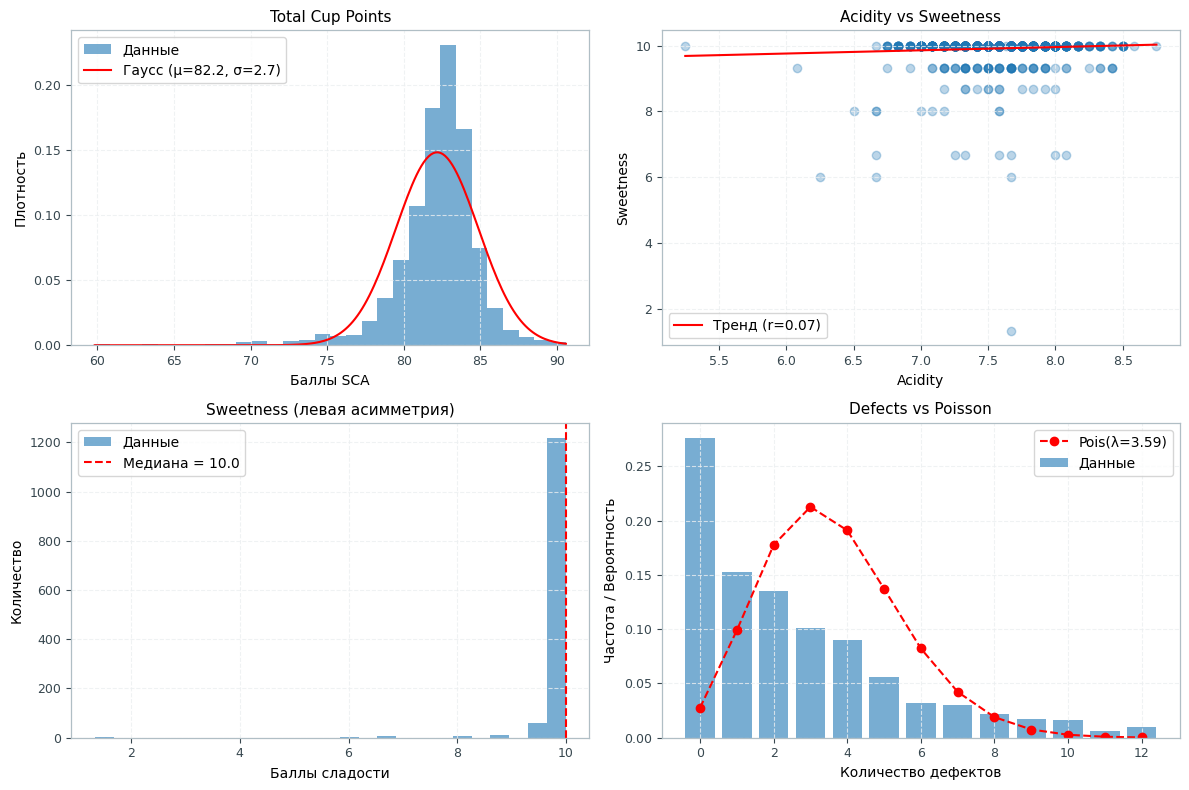

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Total_Points: гистограмма и нормальная кривая
pts = coffee['Total_Points'].dropna()
mu, sigma = pts.mean(), pts.std()

axes[0, 0].hist(pts, bins=30, density=True, alpha=0.6, label='Данные')
x_axis = np.linspace(pts.min(), pts.max(), 200)
axes[0, 0].plot(x_axis, stats.norm.pdf(x_axis, mu, sigma), color='red', label=f'Гаусс (μ={mu:.1f}, σ={sigma:.1f})')
axes[0, 0].set_title('Total Cup Points')
axes[0, 0].set_xlabel('Баллы SCA')
axes[0, 0].set_ylabel('Плотность')
axes[0, 0].legend()
axes[0, 0].grid(True)

# 2. Acidity vs Sweetness: scatter и линия тренда
slope, intercept, r_val, _, _ = stats.linregress(coffee['Acidity'], coffee['Sweetness'])
x_reg = np.linspace(coffee['Acidity'].min(), coffee['Acidity'].max(), 100)

axes[0, 1].scatter(coffee['Acidity'], coffee['Sweetness'], alpha=0.3)
axes[0, 1].plot(x_reg, slope * x_reg + intercept, color='red', label=f'Тренд (r={r_val:.2f})')
axes[0, 1].set_title('Acidity vs Sweetness')
axes[0, 1].set_xlabel('Acidity')
axes[0, 1].set_ylabel('Sweetness')
axes[0, 1].legend()
axes[0, 1].grid(True)

# 3. Sweetness: гистограмма левоасимметричного распределения
#  сразу виден пик на 10 и длинный хвост влево
sweet = coffee['Sweetness'].dropna()
axes[1, 0].hist(sweet, bins=25, alpha=0.6, label='Данные')
axes[1, 0].axvline(sweet.median(), color='red', linestyle='--', label=f'Медиана = {sweet.median():.1f}')
axes[1, 0].set_title('Sweetness (левая асимметрия)')
axes[1, 0].set_xlabel('Баллы сладости')
axes[1, 0].set_ylabel('Количество')
axes[1, 0].legend()
axes[1, 0].grid(True)

# 4. Defects: частоты дефектов и кривая Пуассона
defects = coffee['Defects'].dropna()
lam = defects.mean()
cutoff = 12

val_counts = defects.value_counts(normalize=True).sort_index()
val_counts_cut = val_counts[val_counts.index <= cutoff]

axes[1, 1].bar(val_counts_cut.index, val_counts_cut.values, alpha=0.6, label='Данные')
k_vals = np.arange(0, cutoff + 1)
axes[1, 1].plot(k_vals, stats.poisson.pmf(k_vals, lam), 'ro--', label=f'Pois(λ={lam:.2f})')
axes[1, 1].set_title('Defects vs Poisson')
axes[1, 1].set_xlabel('Количество дефектов')
axes[1, 1].set_ylabel('Частота / Вероятность')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

##ГИПОТЕЗЫ

### 1. Зависимость кислотности и сладости
И кислотность (Acidity), и сладость (Sweetness) — это вкусовые параметры чашки, которые напрямую зависят от накопления сахаров и органических кислот при созревании кофейной ягоды. Чисто химически они связаны метаболизмом растения, поэтому предполагаем, что между ними есть прямая линейная связь.

* $H_0: \rho = 0$ — линейная корреляция отсутствует, кислотность и сладость независимы.
* $H_1: \rho \neq 0$ — связь существует и она статистически значима.

Чтобы это проверить, считаем выборочный коэффициент корреляции Пирсона:

$$r_{xy} = \frac{\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}{\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 \sum_{i=1}^{n} (Y_i - \bar{Y})^2}}$$

А его значимость оцениваем через $t$-критерий Стьюдента:

$$t = r_{xy} \sqrt{\frac{n - 2}{1 - r_{xy}^2}}$$

Строим обычный scatter plot с линией тренда $y = kx + b$. Если $p\text{-value} < 0.05$, то $H_0$ отбрасываем и считаем, что кислотность со сладостью реально растут согласованно.

---

### 2. Дефекты зерен и распределение Пуассона
Дефекты (Category.Two.Defects) — это штучный подсчет бракованных зерен на стандартную навеску в 350 грамм. В теории вероятностей редкие дискретные события на фиксированный объем сырья моделируются распределением Пуассона. Логично было предположить, что зерна портятся независимо друг от друга и дефекты подчиняются именно этому закону.

* $H_0: X \sim \text{Pois}(\lambda)$ — дефекты распределены по Пуассону, то есть дисперсия строго равна среднему: $\mathbb{E}[X] = \mathrm{Var}(X) = \lambda$.
* $H_1: X \nsim \text{Pois}(\lambda)$ — Пуассон не работает из-за сверхдисперсии: $\mathrm{Var}(X) \gg \mathbb{E}[X]$.

Вероятность встретить ровно $k$ дефектов по Пуассону:

$$P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!}$$

Берем выборочное среднее $\bar{X} = \frac{1}{n} \sum X_i$ и несмещенную дисперсию:

$$S^2 = \frac{1}{n - 1} \sum_{i=1}^{n} (X_i - \bar{X})^2$$

И считаем индекс дисперсии $D = S^2 / \bar{X}$, который у честного Пуассона должен вертеться вокруг единицы. Отклонение проверяем через критерий согласия $\chi^2$:

$$\chi^2 = (n - 1) \cdot D = \frac{(n - 1) S^2}{\bar{X}} \sim \chi^2(n - 1)$$

Если на графике теоретический Пуассон идет мимо эмпирических столбиков, а $D \gg 1$, то $H_0$ летит в мусорку. Это значит, что дефекты возникают не поодиночке, а очагами (вредители бьют целые ветки, сушилка перегревает слой зерна), и тут нужно брать отрицательное биномиальное распределение.

---

### 3. Зависимость экспертной оценки от сладости (эффект приторности)
Известно, что некоторые очень любят сладкое и не побоюсь этого сказать зависят от него как от наркотика. Давайте предположим, что с уровнем сладости чашки поднимается и оценка экспертов, но имеет верхний порог, после которого оценки начинают падать (приторность). Будем предполагать, что зависимость выглядит как парабола с вершиной.

Задаем квадратичную модель:

$$\text{Total_Points} = \beta_0 + \beta_1 \cdot \text{Sweetness} + \beta_2 \cdot \text{Sweetness}^2 + \varepsilon$$

* $H_0: \beta_2 = 0$ — приторности нет, связь либо чисто линейная, либо ее вообще нет.
* $H_1: \beta_2 < 0$ — после определенного порога сладости эксперты начинают занижать балл (парабола ветвями вниз).

Коэффициенты ищем обычным МНК через матрицу признаков:

$$\hat{\beta} = (X^T X)^{-1} X^T Y$$

А значимость коэффициента $\beta_2$ проверяем $t$-статистикой:

$$t = \frac{\hat{\beta}_2}{\text{SE}(\hat{\beta}_2)}$$

Если $\beta_2 < 0$ окажется значимым ($p < 0.05$), то пик сладости считаем через производную: $\text{Sweetness}_{\text{max}} = -\beta_1 / (2\beta_2)$. На графике смотрим, загибается ли парабола вниз в пределах реальной шкалы каппинга (до 10 баллов) или дегустаторам сахара всегда мало.

---

### 4. Влияют ли визуальные дефекты зерна на итоговую оценку чашки?
В самом начале мы сделали ремарку, что вторичные дефекты (Defects) — это чисто внешние косяки зеленого зерна (битые, колотые или слегка помятые зерна). Если подумать логически: дегустатор пробует кофе уже после того, как его смололи в порошок и заварили водой. Жерновам кофемолки абсолютно все равно, было зерно целым или треснутым.

Делим данные на две группы: чистый кофе ($0$ дефектов) и дефектный ($\ge 5$ дефектов), и смотрим, есть ли реальная разница в среднем балле чашки.

* $H_0: \mu_{\text{clean}} = \mu_{\text{def}}$ — помол все уравнивает, средние баллы у чистого и дефектного зерна одинаковые.
* $H_1: \mu_{\text{clean}} > \mu_{\text{def}}$ — даже механические дефекты роняют итоговую оценку.

Считаем средние по группам $\bar{X}_1$ и $\bar{X}_2$, а дальше прогоняем через $t$-критерий Уэлча (с поправкой на то, что дисперсии в группах могут различаться):

$$t = \frac{\bar{X}_1 - \bar{X}_2}{\sqrt{\frac{S_1^2}{n_1} + \frac{S_2^2}{n_2}}}$$

Число степеней свободы берем по формуле Уэлча — Саттертуэйта:

$$\nu \approx \frac{\left(\frac{S_1^2}{n_1} + \frac{S_2^2}{n_2}\right)^2}{\frac{(S_1^2 / n_1)^2}{n_1 - 1} + \frac{(S_2^2 / n_2)^2}{n_2 - 1}}$$

Смотрим на boxplot двух групп и на $p\text{-value}$. Если $p < 0.05$, $H_0$ отвергаем: значит, при обжарке колотые зерна сгорают быстрее и дают горечь, либо эксперт видит дефекты в бланке и подсознательно занижает оценку.

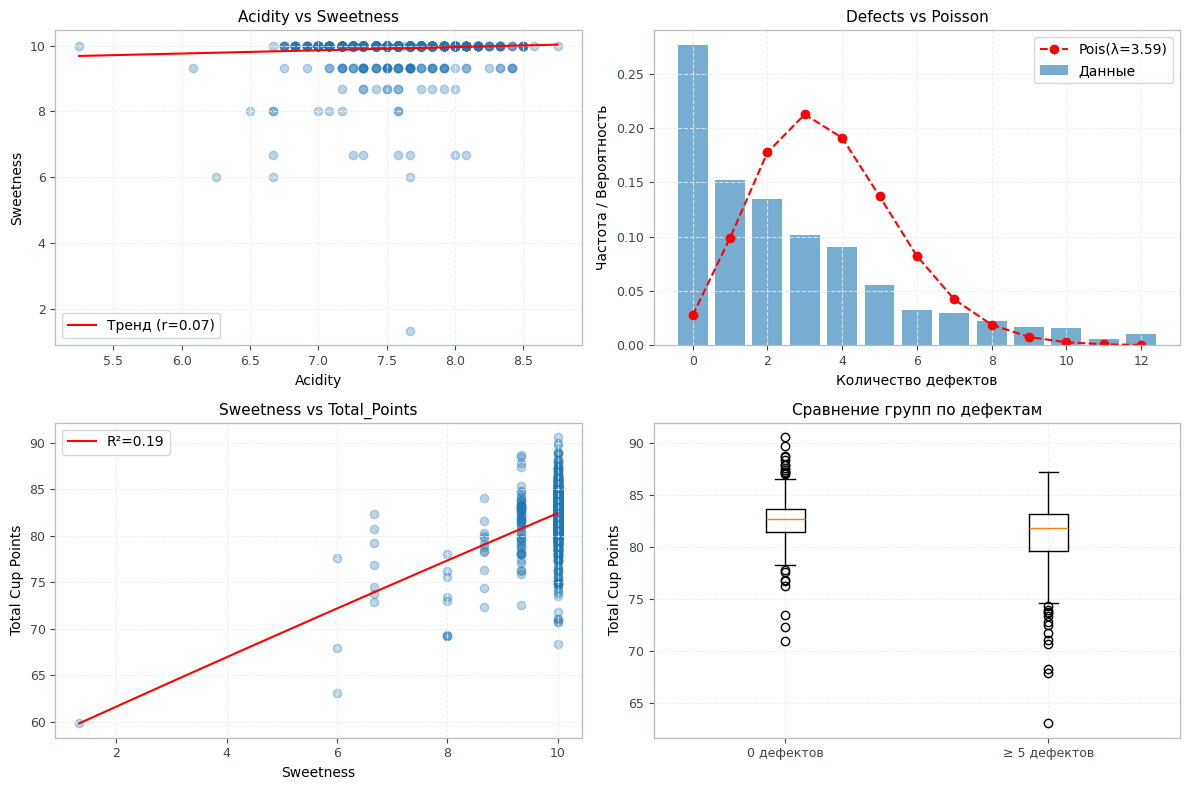

1. Пирсон: r = 0.0690, p-val = 1.2462e-02
2. Пуассон: λ = 3.593, Var = 28.646, D = S²/λ = 7.973
3. Квадрат: β₂ = -0.0093, p-val = 0.8572, R² = 0.189, Пик = 145.7
4. Уэлч: Среднее (0) = 82.58, Среднее (≥5) = 81.08, t = 7.050, p-val = 5.3156e-12


/tmp/ipykernel_1230/2246206523.py:63: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"3. Квадрат: β₂ = {b2:.4f}, p-val = {poly_model.pvalues[2]:.4f}, R² = {poly_model.rsquared:.3f}, Пик = {-b1/(2*b2):.1f}")


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Acidity vs Sweetness (пирсон)
r_val, p_val1 = stats.pearsonr(coffee['Acidity'], coffee['Sweetness'])

axes[0, 0].scatter(coffee['Acidity'], coffee['Sweetness'], alpha=0.3)
slope, intercept = np.polyfit(coffee['Acidity'], coffee['Sweetness'], 1)
x_line = np.linspace(coffee['Acidity'].min(), coffee['Acidity'].max(), 100)
axes[0, 0].plot(x_line, slope * x_line + intercept, color='red', label=f'Тренд (r={r_val:.2f})')
axes[0, 0].set_title('Acidity vs Sweetness')
axes[0, 0].set_xlabel('Acidity')
axes[0, 0].set_ylabel('Sweetness')
axes[0, 0].legend()
axes[0, 0].grid(True)

# 2. Defects vs Пуассон (индекс дисперсии)
defects = coffee['Defects']
mean_def, var_def = defects.mean(), defects.var()
disp_index = var_def / mean_def

cutoff = 12
val_counts = defects.value_counts(normalize=True).sort_index()
val_counts_cut = val_counts[val_counts.index <= cutoff]

axes[0, 1].bar(val_counts_cut.index, val_counts_cut.values, alpha=0.6, label='Данные')
k_vals = np.arange(0, cutoff + 1)
axes[0, 1].plot(k_vals, stats.poisson.pmf(k_vals, mean_def), 'ro--', label=f'Pois(λ={mean_def:.2f})')
axes[0, 1].set_title('Defects vs Poisson')
axes[0, 1].set_xlabel('Количество дефектов')
axes[0, 1].set_ylabel('Частота / Вероятность')
axes[0, 1].legend()
axes[0, 1].grid(True)

# 3. Sweetness -> Total_Points (Квадратичная регрессия)
X_poly = sm.add_constant(np.column_stack([coffee['Sweetness'], coffee['Sweetness']**2]))
poly_model = sm.OLS(coffee['Total_Points'], X_poly).fit()
b0, b1, b2 = poly_model.params

axes[1, 0].scatter(coffee['Sweetness'], coffee['Total_Points'], alpha=0.3)
x_curve = np.linspace(coffee['Sweetness'].min(), 10.0, 100)
axes[1, 0].plot(x_curve, b0 + b1 * x_curve + b2 * (x_curve**2), color='red', label=f'R²={poly_model.rsquared:.2f}')
axes[1, 0].set_title('Sweetness vs Total_Points')
axes[1, 0].set_xlabel('Sweetness')
axes[1, 0].set_ylabel('Total Cup Points')
axes[1, 0].legend()
axes[1, 0].grid(True)

# 4. Сравнение групп по дефектам (t-тест Уэлча)
clean = coffee[coffee['Defects'] == 0]['Total_Points']
defective = coffee[coffee['Defects'] >= 5]['Total_Points']
t_stat4, p_val4 = stats.ttest_ind(clean, defective, equal_var=False)

axes[1, 1].boxplot([clean, defective], tick_labels=['0 дефектов', '≥ 5 дефектов'])
axes[1, 1].set_title('Сравнение групп по дефектам')
axes[1, 1].set_ylabel('Total Cup Points')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

print(f"1. Пирсон: r = {r_val:.4f}, p-val = {p_val1:.4e}")
print(f"2. Пуассон: λ = {mean_def:.3f}, Var = {var_def:.3f}, D = S²/λ = {disp_index:.3f}")
print(f"3. Квадрат: β₂ = {b2:.4f}, p-val = {poly_model.pvalues[2]:.4f}, R² = {poly_model.rsquared:.3f}, Пик = {-b1/(2*b2):.1f}")
print(f"4. Уэлч: Среднее (0) = {clean.mean():.2f}, Среднее (≥5) = {defective.mean():.2f}, t = {t_stat4:.3f}, p-val = {p_val4:.4e}")

По графикам и таблице видно, что наши параметры ведут себя по разному. Итоговый балл (Total_Points) и кислотность (Acidity) — непрерывные величины, которые дают симметричный колокол нормального распределения Гаусса $\mathcal{N}(\mu, \sigma^2)$, так как складываются из множества независимых оценок каппинга. Среднее и медиана тут почти совпадают (около 82.5 и 7.5 баллов), асимметрия близка к нулю, а почти все партии лежат в пределах трех сигм. Сладость (Sweetness) — наоборот, жестко левоасимметрична (Skewness $< 0$, Kurtosis $\gg 0$): почти 90% кофе упирается в потолок шкалы 10 баллов, поэтому среднее тут бесполезно, и смотреть нужно на медиану (10.0). Вторичные дефекты (Defects) — дискретная счетная величина, которая теоретически должна идти по Пуассону $\text{Pois}(\lambda)$, где среднее равно дисперсии. Но у нас при среднем 3.6 дисперсия раздута до 28.6: брак возникает не поодиночке, а пачками из-за вредителей или ошибок сушки, поэтому простой Пуассон ломается и дает сверхдисперсию.

##Результаты по гипотезам
## Результаты проверки гипотез и выводы

### 1. Связь кислотности и сладости
Формально мы получили $p\text{-value} = 0.0125 < 0.05$ при $t = 2.5023$ ($\text{df} = 1308$), так что по учебнику нулевую гипотезу $H_0$ мы отвергаем. Но если включить голову и посмотреть на сам коэффициент корреляции Пирсона $r = 0.0690$, видно, что линейная связь тут практически нулевая (меньше $7\%$).

Почему тогда критерий показал статистическую значимость? Чисто из-за огромного объема выборки ($N = 1310$), на котором даже минимальное отклонение от нуля дает маленький $p\text{-value}$. А реальная причина такого крошечного $r$ лежит в устройстве самой шкалы: в датасете собрана качественная арабика, у которой сладость почти во всех партиях тупо уперлась в потолок $10.0$ баллов. Когда одна величина зажата на максимуме и почти не варьируется, нормальную линейную корреляцию с кислотностью она математически дать не может.

---

### 2. Дефекты зерен и распределение Пуассона
Тут нулевая гипотеза $H_0$ разлетается без малейших шансов: при выборочном среднем $\hat{\lambda} = 3.5931$ дисперсия улетела в $S^2 = 28.6464$. Индекс дисперсии составил $D = 7.9725$ (вместо теоретической единицы у честного Пуассона), а статистика $\chi^2 = 10436.07$ дает $p\text{-value} \approx 0$.

Модель Пуассона здесь полностью проваливается из-за жесткой сверхдисперсии. В реальной жизни это объясняется тем, что зерна не портятся поодиночке и независимо друг от друга. Если плантацию побил вредитель, в мешок попала влага или фермер перегрел сушилку, дефекты возникают сразу очагами (кластерами). Из-за таких локальных вспышек брака дисперсия раздувается в $8$ раз относительно среднего, и описывать этот процесс нужно уже отрицательным биномиальным распределением.

---

### 3. Эффект приторности (сладость и итоговый балл)
Наша идея с параболой и «передозом сладкого» не подтвердилась — нулевую гипотезу $H_0$ оставляем в силе. Коэффициент при квадрате получился околонулевым ($\beta_2 = -0.0093$) со стандартной ошибкой $\text{SE}(\beta_2) = 0.0517$, а огромное значение $p\text{-value} = 0.8572$ ($t = -0.1799$) прямо говорит, что квадратичный изгиб тут — обычный статистический шум.

Самое наглядное получается, если посмотреть на расчетную вершину параболы: точка экстремума $-\beta_1 / (2\beta_2)$ улетела на отметку $145.70$ баллов при том, что вся шкала сладости физически заканчивается на $10.0$. Вывод простой: черный кофе — это не сахарный сироп, концентрация натуральных сахаров при экстракции водой слишком мала, чтобы вызвать у рецепторов ощущение приторности. В пределах реальной шкалы связь работает строго в плюс ($\beta_1 = 2.7116$, $R^2 = 0.1890$): чем больше натуральной сладости сохранилось в зерне, тем охотнее эксперты накидывают итоговый балл.

---

### 4. Парадокс кофемолки (влияние механических дефектов на оценку)
Здесь нулевая гипотеза $H_0$ отвергается с огромным запасом: $t$-статистика Уэлча составила $7.0503$ ($\nu = 556.25$), а $p\text{-value} = 5.32 \times 10^{-12}$. Партии без дефектов ($N_1 = 362$) получают в среднем $\bar{X}_1 = 82.58$ балла, а зерно с пятью и более дефектами ($N_2 = 320$) проседает до $\bar{X}_2 = 81.08$ балла.

Разница в $1.50$ балла может показаться небольшой только со стороны, но для спешелти-индустрии (где основная масса оценок зажата в узком коридоре $80\text{--}85$ баллов) полтора балла — это пропасть между отличным дорогим лотом и посредственным коммерческим кофе. Заодно видно, как у дефектного зерна расползается стандартное отклонение ($S_2 = 3.20$ против $S_1 = 2.20$), то есть качество становится гораздо менее предсказуемым. Кофемолка действительно смалывает все одинаково, но физика ломается раньше — на этапе обжарки: расколотые зерна и мелкие обломки имеют меньшую массу и быстрее прожариваются в ростере, из-за чего банально подгорают раньше целых зерен и дают в чашку горечь и пепельный привкус.

### Анализ численный

In [ ]:
statistic = pd.DataFrame({col: column_anal(coffee[col]) for col in coffee}).T # прогоняем каждый столбец через column_anal и складываем все в одну таблицу
display(statistic)

,Count,Sum,Mean,Median,Mode,Std,Variance,q25,q75,IQR,Skewness,Kurtosis
Total_Points,1310.0,107653.98,82.178611,82.5,83.17,2.686039,7.214804,81.17,83.67,2.50,-1.839283,9.044823
Acidity,1310.0,9875.91,7.538863,7.5,7.50,0.319912,0.102344,7.33,7.75,0.42,-0.200580,2.710941
Sweetness,1310.0,12983.19,9.910832,10.0,10.00,0.454991,0.207017,10.00,10.00,0.00,-9.254962,123.019499
Defects,1310.0,4707.00,3.593130,2.0,0.00,5.352233,28.646400,0.00,4.00,4.00,3.646885,19.800146


##2.5

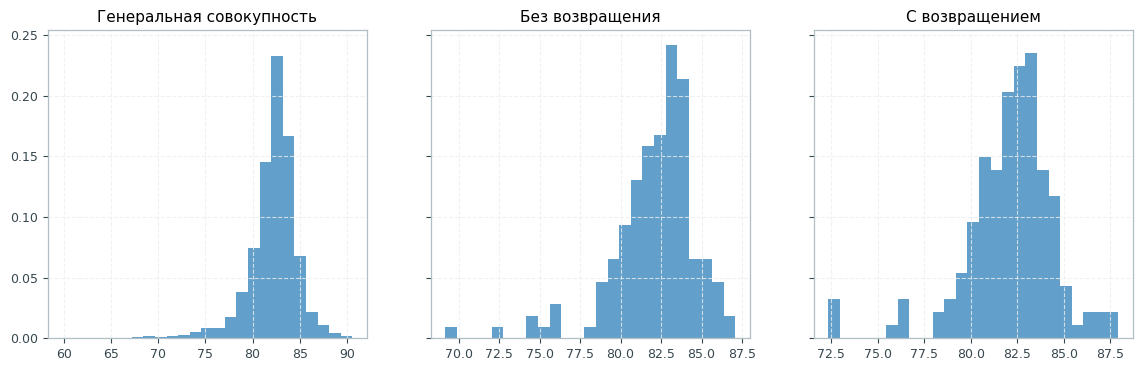

In [ ]:
# извлекаем выборки n=150
sample_without = coffee['Total_Points'].sample(150, replace=False, random_state=42)
sample_with = coffee['Total_Points'].sample(150, replace=True, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

coffee['Total_Points'].hist(ax=axes[0], bins=25, density=True, alpha=0.7)
axes[0].set_title('Генеральная совокупность')

sample_without.hist(ax=axes[1], bins=25, density=True, alpha=0.7)
axes[1].set_title('Без возвращения')

sample_with.hist(ax=axes[2], bins=25, density=True, alpha=0.7)
axes[2].set_title('С возвращением')

plt.show()

2.5 вывод: Берем из генеральной совокупности случайную выборку $n = 150$ двумя способами — без возвращения (`replace=False`) и с возвращением (`replace=True`). Сравниваем их выборочные метрики со всей совокупностью, чтобы оценить репрезентативность и посмотреть, как повторный отбор влияет на дисперсию и форму распределения.

# Lab01 - sprint 2


В этой части нас инетресует генератор случайных чисел, и все с этим связанное